In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"


In [4]:
df= pd.read_csv(r"C:\Users\sohai\Downloads\HHS_Unaccompanied_Alien_Children_Program.csv")
df

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.00,18.00,11.00,"2,484",14.00
1,"December 18, 2025",11.00,50.00,6.00,"2,472",16.00
2,"December 17, 2025",7.00,31.00,11.00,"2,481",10.00
3,"December 16, 2025",8.00,54.00,15.00,"2,468",9.00
4,"December 15, 2025",11.00,42.00,9.00,"2,470",7.00
...,...,...,...,...,...,...
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.columns
print(df.columns.tolist())

# Starting ke 5 records
print("\nFirst 5 Records:")
display(df.head())

# Last ke 5 records
print("\nLast 5 Records:")
display(df.tail())

['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

First 5 Records:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.00,18.00,11.00,"2,484",14.00
1,"December 18, 2025",11.00,50.00,6.00,"2,472",16.00
2,"December 17, 2025",7.00,31.00,11.00,"2,481",10.00
3,"December 16, 2025",8.00,54.00,15.00,"2,468",9.00
4,"December 15, 2025",11.00,42.00,9.00,"2,470",7.00



Last 5 Records:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN
1169,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print('rows,col:',df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum duplicates:',df.duplicated().sum())
print('\nMissing values :')
print(df.isna().sum().sort_values(ascending=False).head(20))

rows,col: (1170, 6)

columns:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

Num duplicates: 449

Missing values :
Date                                               450
Children apprehended and placed in CBP custody*    450
Children in CBP custody                            450
Children transferred out of CBP custody            450
Children in HHS Care                               450
Children discharged from HHS Care                  450
dtype: int64


In [7]:
for col in df.columns:
    if df[col].nunique() >0:
        print(f'\n{col} value counts:')
        print(df[col].value_counts())


Date value counts:
Date
February 13, 2023    1
February 14, 2023    1
February 15, 2023    1
February 16, 2023    1
February 20, 2023    1
                    ..
December 15, 2025    1
December 16, 2025    1
December 17, 2025    1
December 18, 2025    1
December 21, 2025    1
Name: count, Length: 720, dtype: int64

Children apprehended and placed in CBP custody* value counts:
Children apprehended and placed in CBP custody*
4.00      24
7.00      22
6.00      21
8.00      21
5.00      17
          ..
298.00     1
291.00     1
157.00     1
222.00     1
203.00     1
Name: count, Length: 169, dtype: int64

Children in CBP custody value counts:
Children in CBP custody
230.00    14
22.00     13
285.00    13
18.00     11
245.00    11
          ..
455.00     1
466.00     1
531.00     1
459.00     1
477.00     1
Name: count, Length: 216, dtype: int64

Children transferred out of CBP custody value counts:
Children transferred out of CBP custody
11.00     18
12.00     18
8.00      17
5.00      1

In [8]:
df.describe()

,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children discharged from HHS Care
count,720.00,720.00,720.00,720.00
mean,93.52,171.49,128.67,173.41
std,72.65,126.35,97.32,125.70
min,0.00,7.00,0.00,0.00
25%,12.00,36.00,14.00,19.75
50%,99.00,193.00,157.00,181.00
75%,147.25,263.25,199.25,267.00
max,333.00,531.00,440.00,505.00


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1170 entries, 0 to 1169
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Date                                             720 non-null    object 
 1   Children apprehended and placed in CBP custody*  720 non-null    float64
 2   Children in CBP custody                          720 non-null    float64
 3   Children transferred out of CBP custody          720 non-null    float64
 4   Children in HHS Care                             720 non-null    object 
 5   Children discharged from HHS Care                720 non-null    float64
dtypes: float64(4), object(2)
memory usage: 55.0+ KB


In [11]:
# Make a copy of the original dataset
df_clean = df.copy()

# Convert Date into datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)

# Remove completely blank rows
df_clean = df_clean.dropna(how="all").copy()

# Remove rows where Date is missing
df_clean = df_clean.dropna(subset=["Date"]).copy()

# Numerical columns
numeric_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

# Convert numerical columns
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

# Sort data chronologically
df_clean = df_clean.sort_values(
    "Date"
).reset_index(drop=True)

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

display(df_clean.head())

Original Shape: (1170, 6)
Cleaned Shape: (720, 6)


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33.00,53.00,34.00,6566,436.00
1,2023-01-22,32.00,49.00,39.00,7122,227.00
2,2023-01-23,32.00,50.00,39.00,7280,181.00
3,2023-01-24,47.00,42.00,47.00,7433,175.00
4,2023-01-25,20.00,22.00,41.00,7538,180.00


### find duplicate rows

In [13]:
print("Duplicate Rows:", df_clean.duplicated().sum())

print(
    "Duplicate Dates:",
    df_clean["Date"].duplicated().sum()
)

print("First Date:", df_clean["Date"].min())
print("Last Date:", df_clean["Date"].max())

print("Total Records:", len(df_clean))

Duplicate Rows: 0
Duplicate Dates: 0
First Date: 2023-01-12 00:00:00
Last Date: 2025-12-21 00:00:00
Total Records: 720


### find Missing values

In [14]:
print("Missing Values:")
display(
    df_clean.isnull().sum().to_frame(
        "Missing_Count"))

Missing Values:


,Missing_Count
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0


### find to check Date range data

In [15]:
all_dates = pd.date_range(
    start=df_clean["Date"].min(),
    end=df_clean["Date"].max(),
    freq="D"
)

observed_dates = pd.DatetimeIndex(
    df_clean["Date"].unique()
)

missing_dates = all_dates.difference(
    observed_dates
)

print("Expected Calendar Days:", len(all_dates))
print("Available Dates:", len(observed_dates))
print("Missing Dates:", len(missing_dates))

print("\nFirst 15 Missing Dates:")
print(missing_dates[:15])

Expected Calendar Days: 1075
Available Dates: 720
Missing Dates: 355

First 15 Missing Dates:
DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26', '2023-01-27', '2023-01-28',
               '2023-02-03', '2023-02-04', '2023-02-10'],
              dtype='datetime64[ns]', freq=None)


### Exploratory Data Analysis (EDA)

In [19]:
df_clean[numeric_columns].describe().round(2)

,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720.00,720.00,720.00,720.00,720.00
mean,93.52,171.49,128.67,"6,061.28",173.41
std,72.65,126.35,97.32,"2,833.07",125.70
min,0.00,7.00,0.00,"1,972.00",0.00
25%,12.00,36.00,14.00,"2,467.75",19.75
50%,99.00,193.00,157.00,"6,406.50",181.00
75%,147.25,263.25,199.25,"8,010.25",267.00
max,333.00,531.00,440.00,"11,516.00",505.00


### HHS Care Load Trend

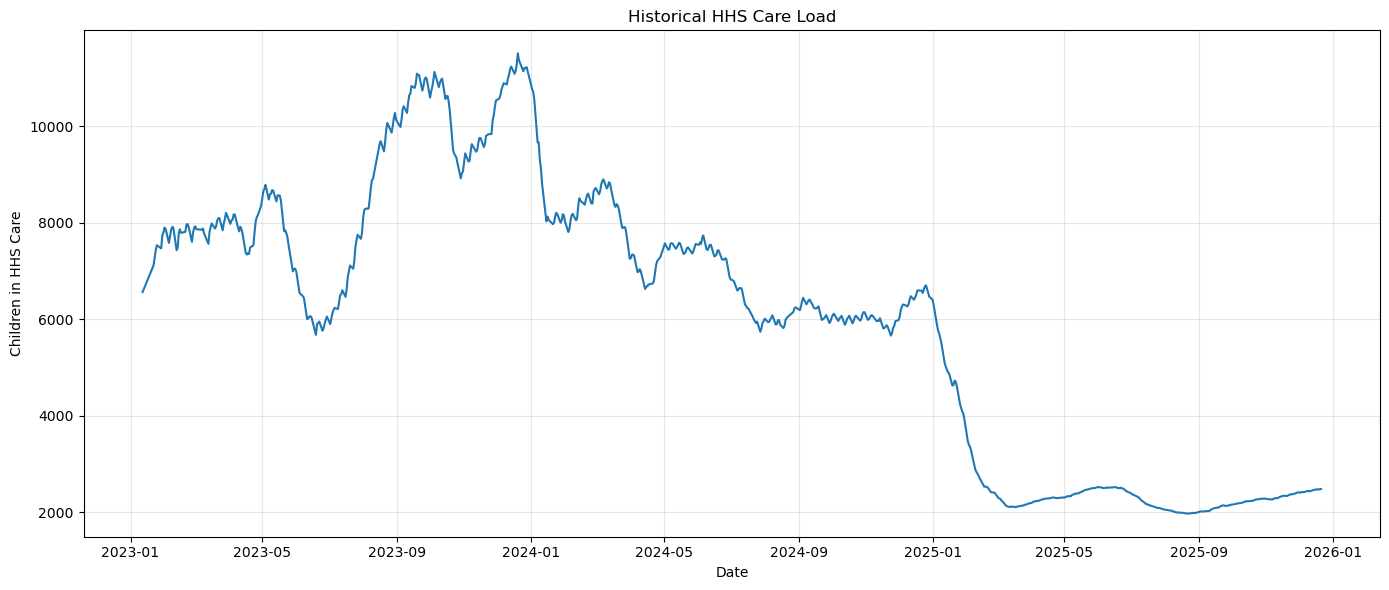

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children in HHS Care"]
)

plt.title("Historical HHS Care Load")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Daily Discharges Trend

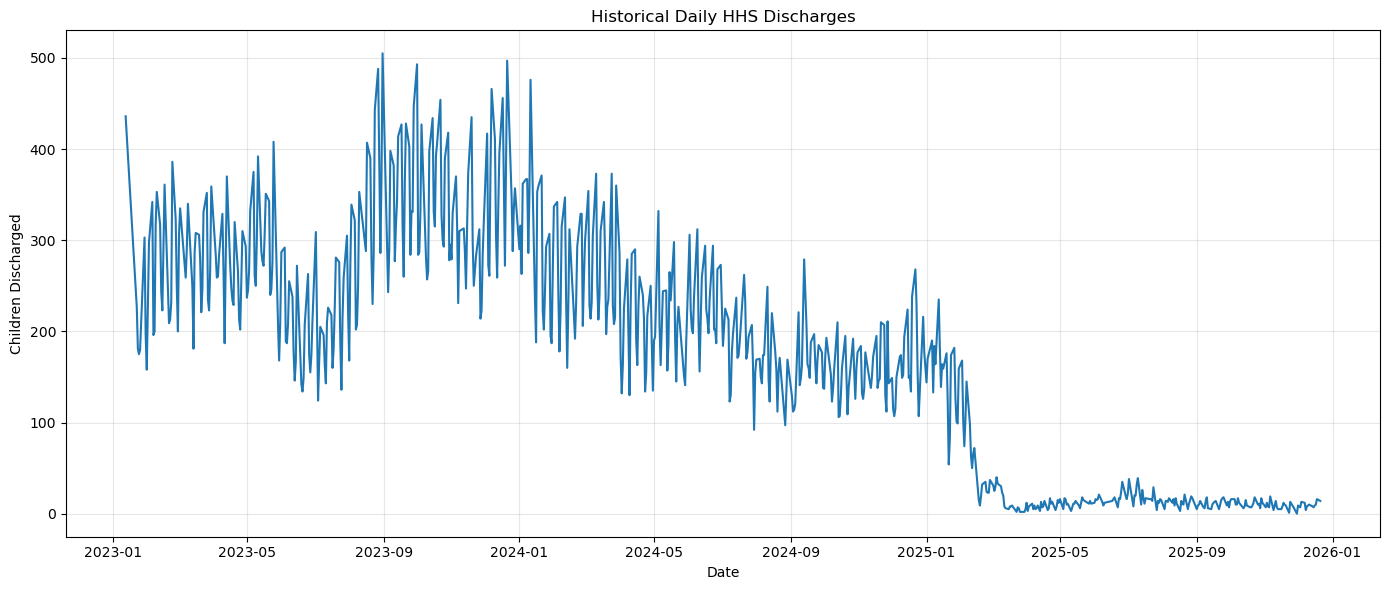

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children discharged from HHS Care"]
)

plt.title("Historical Daily HHS Discharges")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Transfers Trend

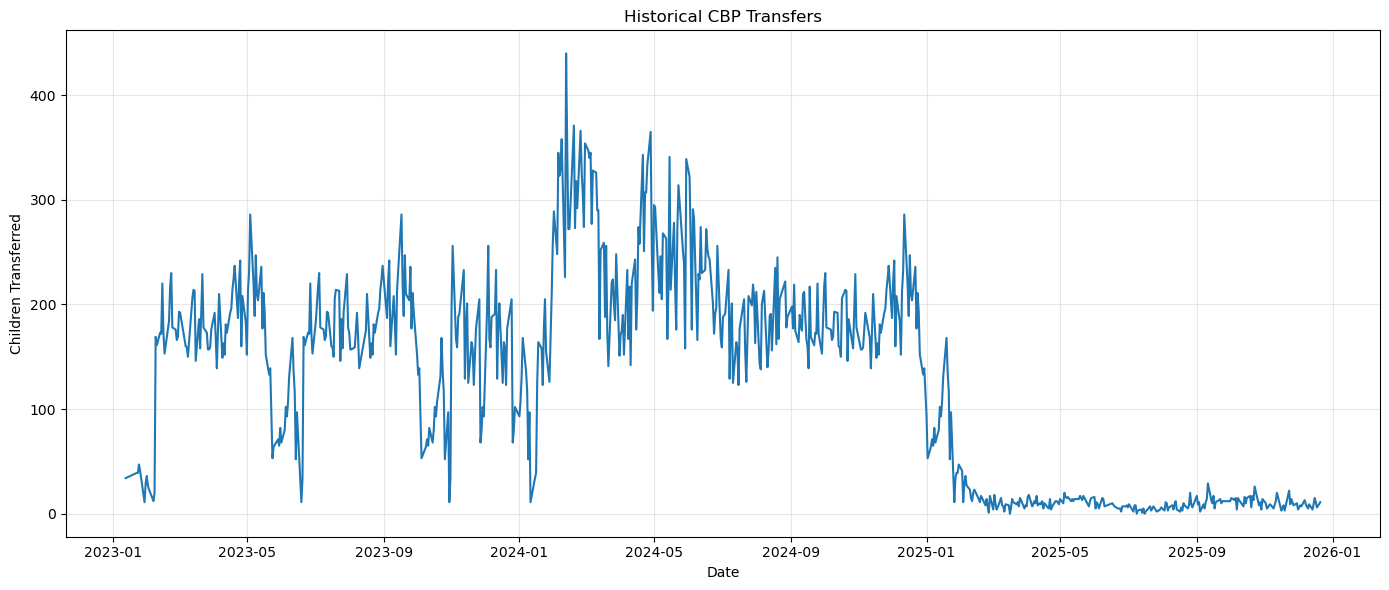

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children transferred out of CBP custody"]
)

plt.title("Historical CBP Transfers")
plt.xlabel("Date")
plt.ylabel("Children Transferred")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Average HHS Care Load

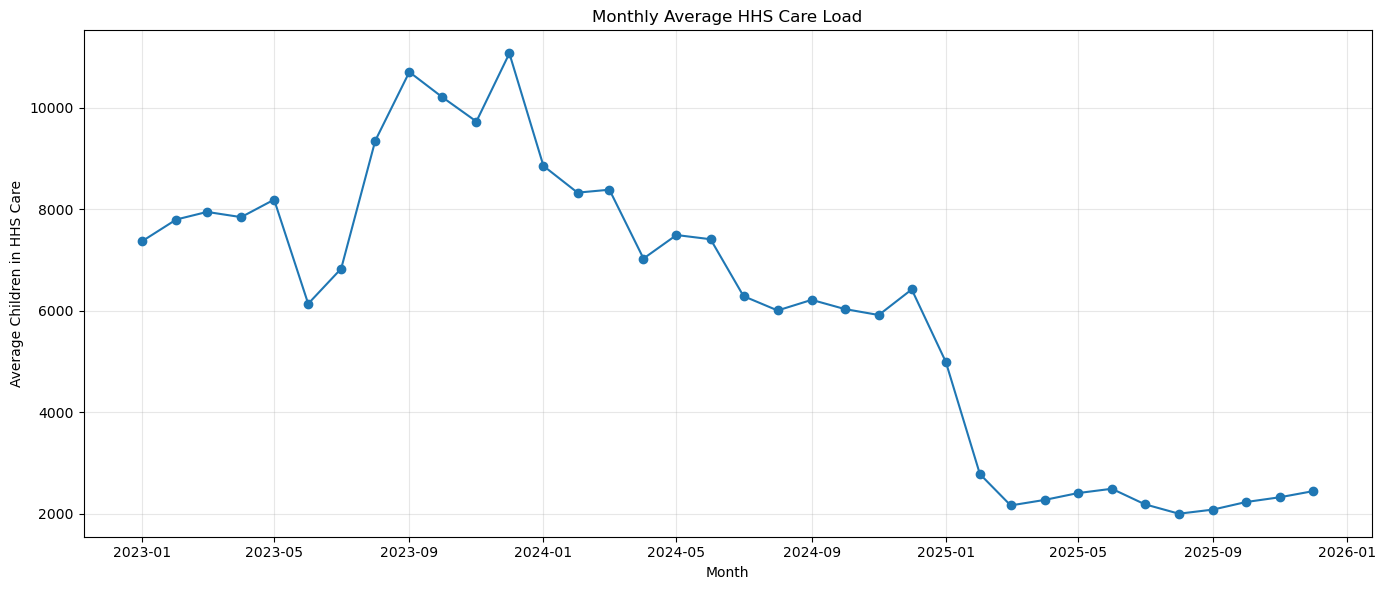

In [23]:
monthly_hhs = (
    df_clean
    .set_index("Date")["Children in HHS Care"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_hhs.index,
    monthly_hhs.values,
    marker="o"
)

plt.title("Monthly Average HHS Care Load")
plt.xlabel("Month")
plt.ylabel("Average Children in HHS Care")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Select numerical columns
numeric_cols = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

# Statistical summary
eda_summary =df_clean[numeric_cols].describe().round(2)

display(eda_summary)

,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720.00,720.00,720.00,720.00,720.00
mean,93.52,171.49,128.67,"6,061.28",173.41
std,72.65,126.35,97.32,"2,833.07",125.70
min,0.00,7.00,0.00,"1,972.00",0.00
25%,12.00,36.00,14.00,"2,467.75",19.75
50%,99.00,193.00,157.00,"6,406.50",181.00
75%,147.25,263.25,199.25,"8,010.25",267.00
max,333.00,531.00,440.00,"11,516.00",505.00


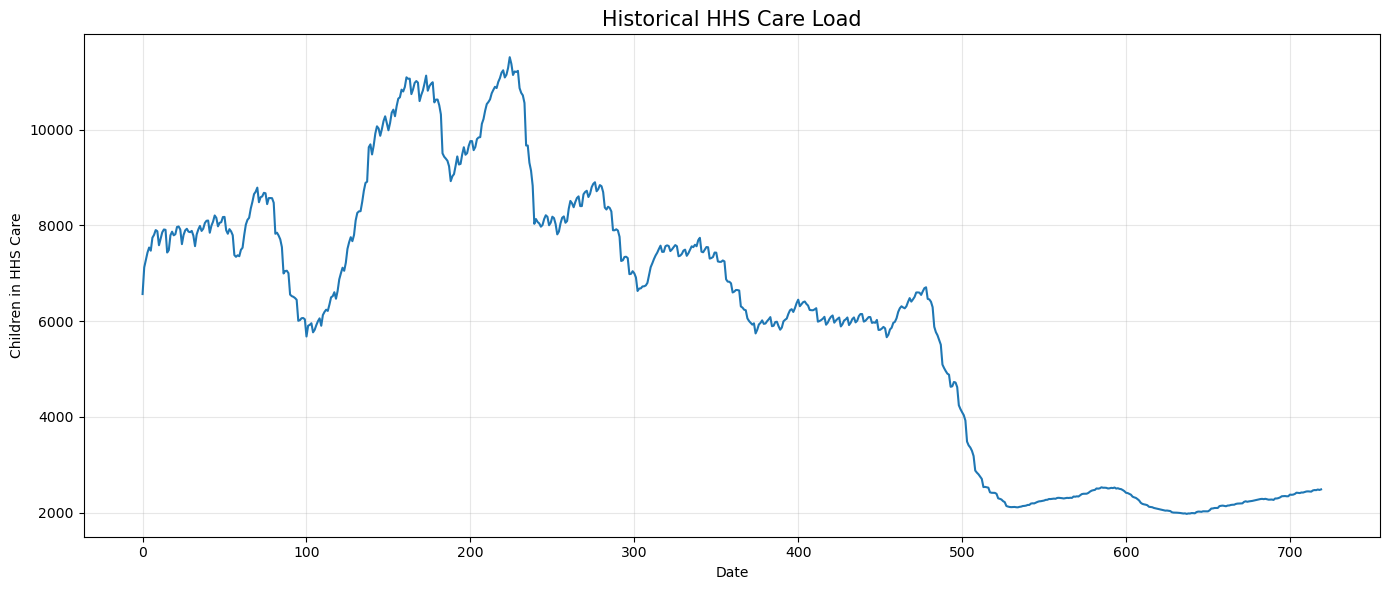

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean.index,
    df_clean["Children in HHS Care"],
    linewidth=1.5
)

plt.title("Historical HHS Care Load", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Historical Daily HHS Discharges Charts

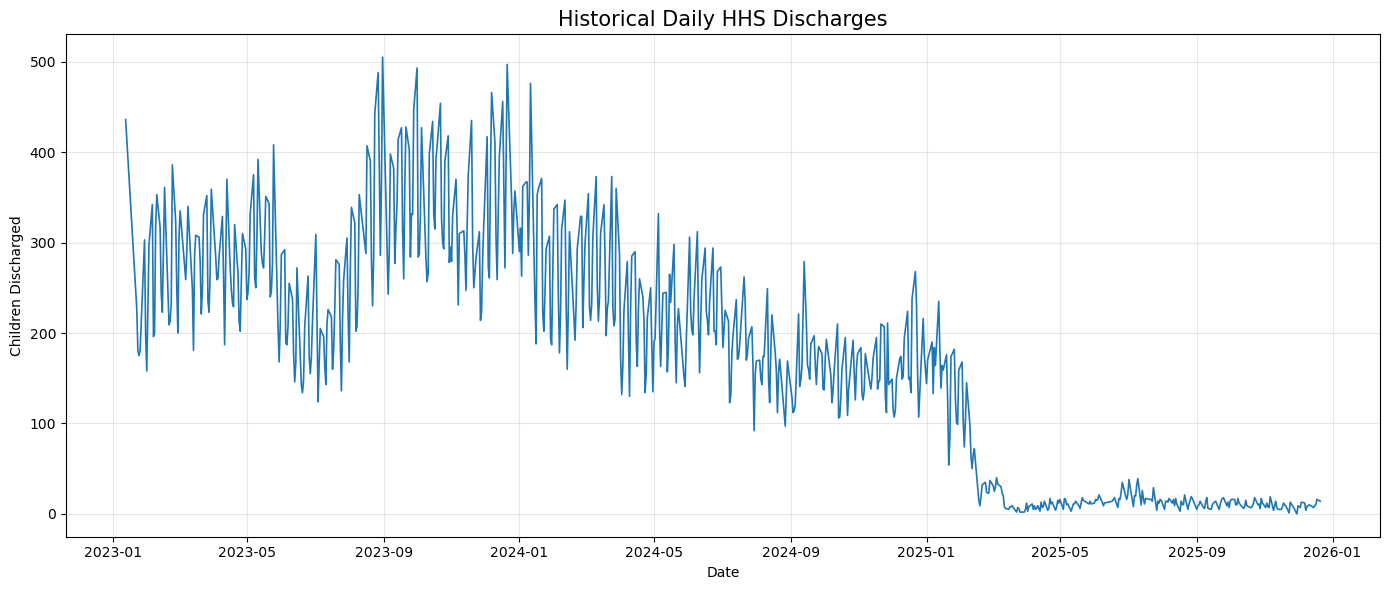

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children discharged from HHS Care"],
    linewidth=1.2
)

plt.title("Historical Daily HHS Discharges", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### CBP Transfers Charts

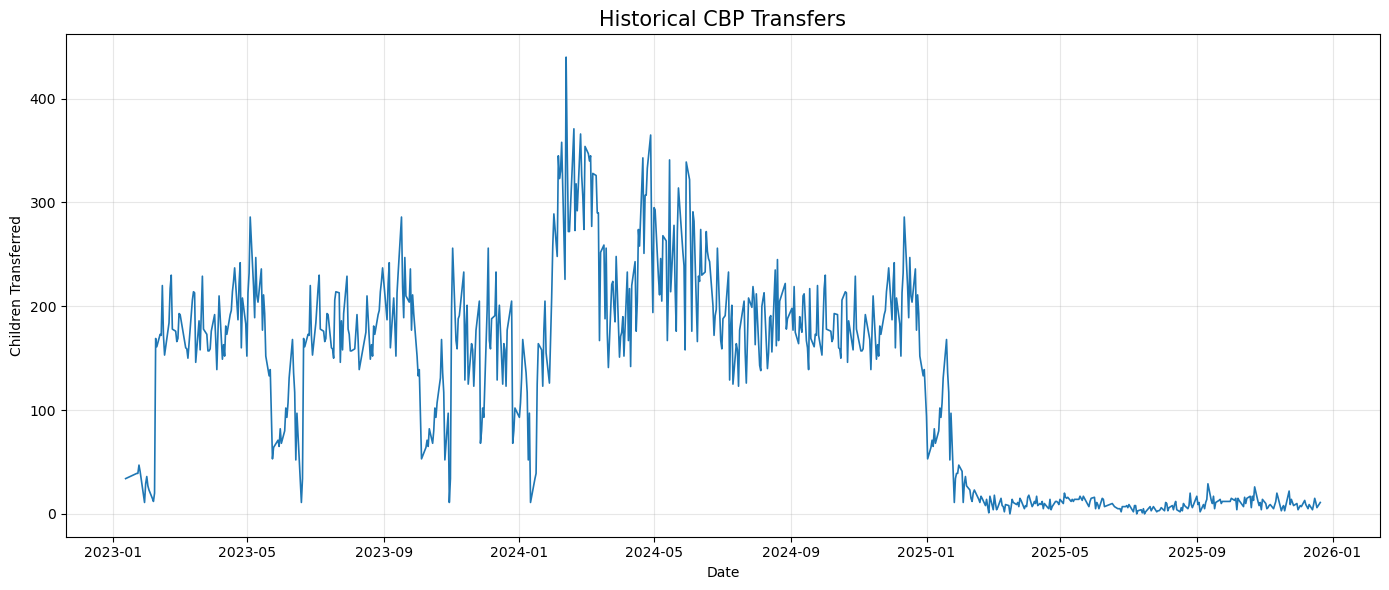

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children transferred out of CBP custody"],
    linewidth=1.2
)

plt.title("Historical CBP Transfers", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Children Transferred")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### EDA Summary

In [35]:
numeric_cols = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

eda_summary = df_clean[numeric_cols].describe().round(2)

display(eda_summary)

,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720.00,720.00,720.00,720.00,720.00
mean,93.52,171.49,128.67,"6,061.28",173.41
std,72.65,126.35,97.32,"2,833.07",125.70
min,0.00,7.00,0.00,"1,972.00",0.00
25%,12.00,36.00,14.00,"2,467.75",19.75
50%,99.00,193.00,157.00,"6,406.50",181.00
75%,147.25,263.25,199.25,"8,010.25",267.00
max,333.00,531.00,440.00,"11,516.00",505.00


### Date Frequency Check

In [36]:
# Sort data by date
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Check duplicate dates
print("Duplicate dates:", df_clean["Date"].duplicated().sum())

# Check gaps between dates
date_gaps = df_clean["Date"].diff().dt.days

print("\nDate gap distribution:")
print(date_gaps.value_counts().sort_index().head(10))

# Show first and last dates
print("\nStart date:", df_clean["Date"].min())
print("End date:", df_clean["Date"].max())

Duplicate dates: 0

Date gap distribution:
Date
1.00     558
2.00      10
3.00     122
4.00      23
5.00       3
6.00       1
7.00       1
10.00      1
Name: count, dtype: int64

Start date: 2023-01-12 00:00:00
End date: 2025-12-21 00:00:00


### Lag Features

In [37]:
# Create a copy for feature engineering
df_features = df_clean.copy()

target_column = "Children in HHS Care"

# Previous observations
df_features["lag_1"] = df_features[target_column].shift(1)

df_features["lag_7"] = df_features[target_column].shift(7)

df_features["lag_14"] = df_features[target_column].shift(14)

# Display results
display(
    df_features[
        ["Date", target_column, "lag_1", "lag_7", "lag_14"]
    ].head(20)
)

,Date,Children in HHS Care,lag_1,lag_7,lag_14
0,2023-01-12,6566,<NA>,<NA>,<NA>
1,2023-01-22,7122,6566,<NA>,<NA>
2,2023-01-23,7280,7122,<NA>,<NA>
3,2023-01-24,7433,7280,<NA>,<NA>
4,2023-01-25,7538,7433,<NA>,<NA>
5,2023-01-29,7472,7538,<NA>,<NA>
6,2023-01-30,7743,7472,<NA>,<NA>
7,2023-01-31,7803,7743,6566,<NA>
8,2023-02-01,7903,7803,7122,<NA>
9,2023-02-02,7879,7903,7280,<NA>


### Seven-Day and Fourteen-Day Average

In [38]:
# Rolling averages based on previous observations only
df_features["rolling_mean_7"] = (
    df_features[target_column]
    .shift(1)
    .rolling(window=7)
    .mean())
df_features["rolling_mean_14"] = (
    df_features[target_column]
    .shift(1)
    .rolling(window=14)
    .mean())
display(
    df_features[
        [
            "Date",
            target_column,
            "rolling_mean_7",
            "rolling_mean_14"
        ]
    ].head(25)
)

,Date,Children in HHS Care,rolling_mean_7,rolling_mean_14
0,2023-01-12,6566,NaN,NaN
1,2023-01-22,7122,NaN,NaN
2,2023-01-23,7280,NaN,NaN
3,2023-01-24,7433,NaN,NaN
4,2023-01-25,7538,NaN,NaN
5,2023-01-29,7472,NaN,NaN
6,2023-01-30,7743,NaN,NaN
7,2023-01-31,7803,"7,307.71",NaN
8,2023-02-01,7903,"7,484.43",NaN
9,2023-02-02,7879,"7,596.00",NaN


### Date Features

In [ ]:
df_features["day_of_week"] = df_features["Date"].dt.dayofweek

df_features["month"] = df_features["Date"].dt.month

df_features["year"] = df_features["Date"].dt.year

display(
    df_features[
        ["Date", "day_of_week", "month", "year"]
    ].head(10)
)

### Check Missing Values

In [ ]:
print("Feature Dataset Shape:", df_features.shape)

print("\nMissing Values:")
display(
    df_features.isnull().sum().to_frame("Missing_Count")
)

print("\nFeature Dataset Preview:")
display(df_features.head(20))

### Save Feature Dataset

In [39]:
OUTPUT_DIR = Path.cwd() / "project_outputs"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FEATURE_PATH = OUTPUT_DIR / "HHS_Feature_Engineered.csv"

df_features.to_csv(
    FEATURE_PATH,
    index=False
)

print("Feature dataset saved successfully!")
print("Location:", FEATURE_PATH.resolve())

Feature dataset saved successfully!
Location: C:\Users\sohai\project_outputs\HHS_Feature_Engineered.csv


In [40]:
# Sort dataset by date
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Generate all calendar dates
all_dates = pd.date_range(
    start=df_clean["Date"].min(),
    end=df_clean["Date"].max(),
    freq="D"
)

# Identify missing dates
existing_dates = pd.DatetimeIndex(df_clean["Date"].unique())

missing_dates = all_dates.difference(existing_dates)

print("Expected Calendar Days:", len(all_dates))
print("Available Reporting Dates:", len(existing_dates))
print("Missing Calendar Dates:", len(missing_dates))
print("Missing Date Percentage:", round(
    len(missing_dates) / len(all_dates) * 100, 2
), "%")

Expected Calendar Days: 1075
Available Reporting Dates: 720
Missing Calendar Dates: 355
Missing Date Percentage: 33.02 %


### Missing Dates Visualisation

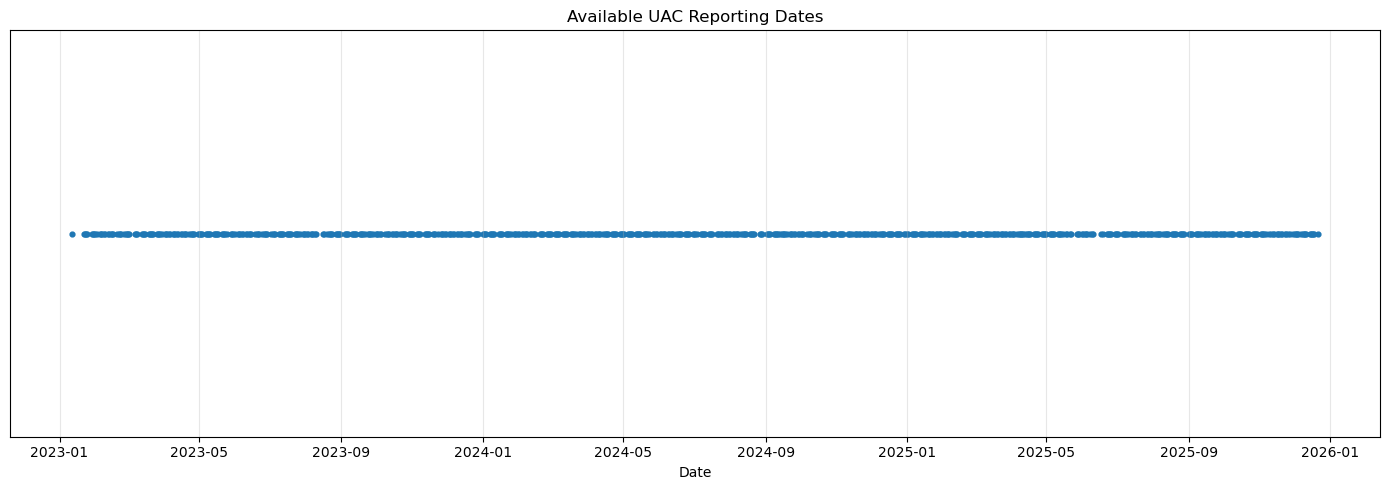

In [41]:
plt.figure(figsize=(14, 5))

plt.scatter(
    df_clean["Date"],
    np.ones(len(df_clean)),
    s=12
)

plt.title("Available UAC Reporting Dates")
plt.xlabel("Date")
plt.yticks([])

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Create Daily Calendar

In [42]:
# Set Date as index
df_daily = df_clean.set_index("Date").sort_index()

# Create a complete daily calendar
df_daily = df_daily.asfreq("D")

print("Daily Calendar Shape:", df_daily.shape)

print("\nMissing Values After Creating Calendar:")
display(
    df_daily.isnull().sum().to_frame("Missing_Count")
)

display(df_daily.head())

Daily Calendar Shape: (1075, 5)

Missing Values After Creating Calendar:


,Missing_Count
Children apprehended and placed in CBP custody*,355
Children in CBP custody,355
Children transferred out of CBP custody,355
Children in HHS Care,355
Children discharged from HHS Care,355


,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
Date,,,,,
2023-01-12,33.00,53.00,34.00,6566,436.00
2023-01-13,<NA>,<NA>,<NA>,<NA>,<NA>
2023-01-14,<NA>,<NA>,<NA>,<NA>,<NA>
2023-01-15,<NA>,<NA>,<NA>,<NA>,<NA>
2023-01-16,<NA>,<NA>,<NA>,<NA>,<NA>


### HHS Care Load And Daily Flows Check

In [43]:
target_columns = [
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

for col in target_columns:
    print(f"\nColumn: {col}")
    print("Missing values:", df_daily[col].isna().sum())
    print("Available values:", df_daily[col].notna().sum())


Column: Children in HHS Care
Missing values: 355
Available values: 720

Column: Children discharged from HHS Care
Missing values: 355
Available values: 720


In [45]:
print("Original cleaned dataset shape:", df_clean.shape)
print("\nMissing values in available observations:")
display(df_clean.isnull().sum().to_frame("Missing_Count"))

print("\nDuplicate dates:", df_clean["Date"].duplicated().sum())

Original cleaned dataset shape: (720, 6)

Missing values in available observations:


,Missing_Count
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0



Duplicate dates: 0


### Create Forecasting Dataset

In [46]:
# Copy the available observations
df_model = df_clean.copy()

# Sort by date
df_model = df_model.sort_values("Date").reset_index(drop=True)

# Keep the two forecasting targets
target_columns = [
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

print("Forecasting dataset shape:", df_model.shape)

display(df_model[["Date"] + target_columns].head())

Forecasting dataset shape: (720, 6)


,Date,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,6566,436.00
1,2023-01-22,7122,227.00
2,2023-01-23,7280,181.00
3,2023-01-24,7433,175.00
4,2023-01-25,7538,180.00


In [47]:
# HHS Care Load target
y = df_model["Children in HHS Care"]

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(df_model) * 0.80)

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

test_dates = df_model["Date"].iloc[split_index:]

print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))

print("Training end date:", df_model["Date"].iloc[split_index - 1])
print("Testing start date:", test_dates.iloc[0])

Training observations: 576
Testing observations: 144
Training end date: 2025-05-13 00:00:00
Testing start date: 2025-05-14 00:00:00


### Naive Forecasting Model

In [52]:
naive_value = y_train.iloc[-1]
naive_predictions = pd.Series(
    naive_value,
    index=y_test.index)

print("Latest training value:", naive_value)

display(
    pd.DataFrame({
        "Date": test_dates.values,
        "Actual_HHS_Care": y_test.values,
        "Predicted_HHS_Care": naive_predictions.values
    }).head(10))

Latest training value: 2394


,Date,Actual_HHS_Care,Predicted_HHS_Care
0,2025-05-14,2394,2394
1,2025-05-15,2410,2394
2,2025-05-18,2437,2394
3,2025-05-19,2457,2394
4,2025-05-21,2467,2394
5,2025-05-22,2473,2394
6,2025-05-27,2504,2394
7,2025-05-28,2499,2394
8,2025-05-29,2506,2394
9,2025-06-01,2528,2394


### Model Evaluation MAE, RMSE and MAPE

In [49]:
mae = mean_absolute_error(
    y_test,
    naive_predictions)
rmse = np.sqrt(
    mean_squared_error(y_test, naive_predictions))

nonzero_mask = y_test != 0

if nonzero_mask.any():
    mape = (
        np.abs(
            (y_test[nonzero_mask] - naive_predictions[nonzero_mask])
            / y_test[nonzero_mask]
        ).mean() * 100)
else:
    mape = np.nan

print("Naive Forecast Results")
print("----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE (%):", round(mape, 2) if pd.notna(mape) else "Undefined")

Naive Forecast Results
----------------------
MAE: 186.51
RMSE: 227.23
MAPE (%): 8.76


### Compare Predictions charts

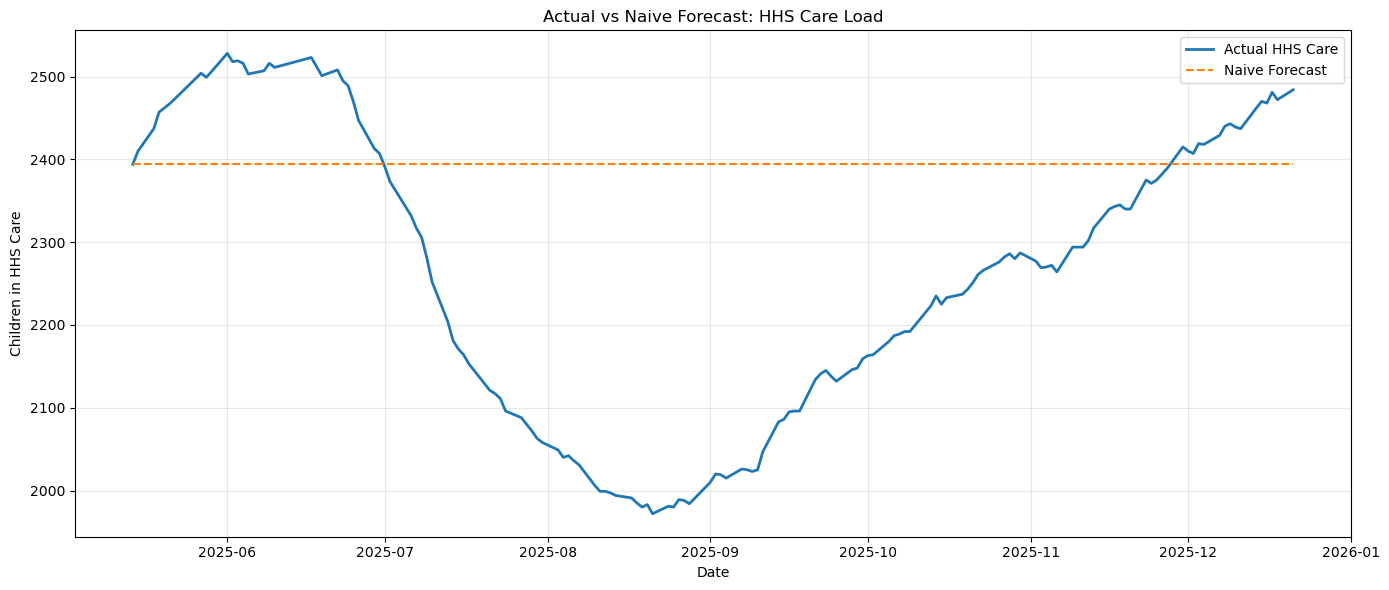

In [50]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test.values,
    label="Actual HHS Care",
    linewidth=2
)

plt.plot(
    test_dates,
    naive_predictions.values,
    label="Naive Forecast",
    linestyle="--"
)

plt.title("Actual vs Naive Forecast: HHS Care Load")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
window_size = 7

moving_avg_predictions = []

history = list(y_train.values)

for actual_value in y_test.values:

    prediction = np.mean(history[-window_size:])

    moving_avg_predictions.append(prediction)

    history.append(actual_value)
    
moving_avg_predictions = pd.Series(
    moving_avg_predictions,
    index=y_test.index
)
print("Moving Average Model created successfully!")

display(
    pd.DataFrame({
        "Date": test_dates.values,
        "Actual_HHS_Care": y_test.values,
        "Moving_Average_Forecast": moving_avg_predictions.values
    }).head(10))

Moving Average Model created successfully!


,Date,Actual_HHS_Care,Moving_Average_Forecast
0,2025-05-14,2394,"2,362.43"
1,2025-05-15,2410,"2,371.43"
2,2025-05-18,2437,"2,381.57"
3,2025-05-19,2457,"2,396.14"
4,2025-05-21,2467,"2,409.86"
5,2025-05-22,2473,"2,421.57"
6,2025-05-27,2504,"2,433.14"
7,2025-05-28,2499,"2,448.86"
8,2025-05-29,2506,"2,463.86"
9,2025-06-01,2528,"2,477.57"


In [54]:
mae_ma = mean_absolute_error(
    y_test,
    moving_avg_predictions)

rmse_ma = np.sqrt(
    mean_squared_error(y_test, moving_avg_predictions))

nonzero_mask = y_test != 0

if nonzero_mask.any():
    mape_ma = (
        np.abs(
            (y_test[nonzero_mask] - moving_avg_predictions[nonzero_mask])
            / y_test[nonzero_mask]
        ).mean() * 100)
else:
    mape_ma = np.nan

print("Moving Average Model Results")
print("-----------------------------")
print("MAE:", round(mae_ma, 2))
print("RMSE:", round(rmse_ma, 2))
print(
    "MAPE (%):",
    round(mape_ma, 2) if pd.notna(mape_ma) else "Undefined")

Moving Average Model Results
-----------------------------
MAE: 33.25
RMSE: 40.61
MAPE (%): 1.48


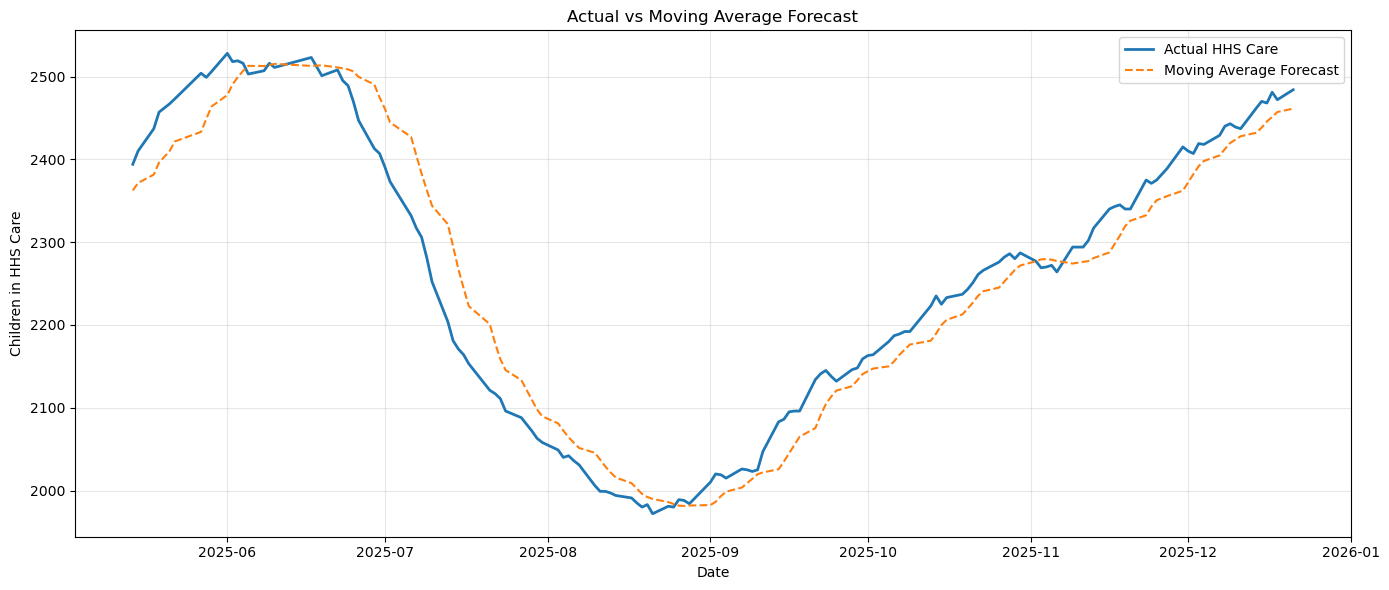

In [55]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test.values,
    label="Actual HHS Care",
    linewidth=2)

plt.plot(
    test_dates,
    moving_avg_predictions.values,
    label="Moving Average Forecast",
    linestyle="--")

plt.title("Actual vs Moving Average Forecast")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "Moving Average"],
    "MAE": [
        mae,
        mae_ma],
    "RMSE": [
        rmse,
        rmse_ma],
    "MAPE (%)": [
        mape,
        mape_ma]})
display(model_comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,186.51,227.23,8.76
1,Moving Average,33.25,40.61,1.48


In [59]:
df_features = df_clean.copy()
df_features = df_features.sort_values(
    "Date"
).reset_index(drop=True)
target = "Children in HHS Care"
df_features["lag_1"] = (
    df_features[target].shift(1))
df_features["lag_7"] = (
    df_features[target].shift(7))
df_features["lag_14"] = (
    df_features[target].shift(14))
df_features["rolling_mean_7"] = (
    df_features[target]
    .shift(1)
    .rolling(window=7)
    .mean())
df_features["rolling_mean_14"] = (
    df_features[target]
    .shift(1)
    .rolling(window=14)
    .mean())
df_features["day_of_week"] = (
    df_features["Date"].dt.dayofweek)
df_features["month"] = (
    df_features["Date"].dt.month)
df_features = df_features.dropna().reset_index(drop=True)

print("Feature engineering completed!")
print("Dataset shape:", df_features.shape)

display(df_features.head())

Feature engineering completed!
Dataset shape: (706, 13)


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,day_of_week,month
0,2023-02-09,124.00,234.00,161.00,7908,353.00,7915,7803,6566,"7,808.71","7,558.21",3,2
1,2023-02-12,92.00,203.00,173.00,7434,317.00,7908,7903,7122,"7,823.71","7,654.07",6,2
2,2023-02-13,186.00,259.00,172.00,7483,244.00,7434,7879,7280,"7,756.71","7,676.36",0,2
3,2023-02-14,154.00,225.00,220.00,7794,223.00,7483,7586,7433,"7,700.14","7,690.86",1,2
4,2023-02-15,91.00,199.00,172.00,7869,290.00,7794,7720,7538,"7,729.86","7,716.64",2,2


In [60]:
feature_columns = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "day_of_week",
    "month"]
X = df_features[feature_columns]
y_rf = df_features[target]
split_index = int(len(df_features) * 0.80)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train_rf = y_rf.iloc[:split_index]
y_test_rf = y_rf.iloc[split_index:]
test_dates_rf = df_features["Date"].iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training end date:",
    df_features["Date"].iloc[split_index - 1])
print(
    "Testing start date:",
    test_dates_rf.iloc[0])

Training rows: 564
Testing rows: 142
Training end date: 2025-05-15 00:00:00
Testing start date: 2025-05-18 00:00:00


In [61]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42)
rf_model.fit(X_train, y_train_rf)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [62]:
rf_predictions = rf_model.predict(X_test)

print("Random Forest predictions generated!")

rf_results = pd.DataFrame({
    "Date": test_dates_rf.values,
    "Actual_HHS_Care": y_test_rf.values,
    "Predicted_HHS_Care": rf_predictions})
display(rf_results.head(10))

Random Forest predictions generated!


,Date,Actual_HHS_Care,Predicted_HHS_Care
0,2025-05-18,2437,"2,399.49"
1,2025-05-19,2457,"2,402.55"
2,2025-05-21,2467,"2,402.41"
3,2025-05-22,2473,"2,402.03"
4,2025-05-27,2504,"2,406.46"
5,2025-05-28,2499,"2,411.72"
6,2025-05-29,2506,"2,411.16"
7,2025-06-01,2528,"2,412.16"
8,2025-06-02,2518,"2,429.96"
9,2025-06-03,2519,"2,413.52"


In [63]:
rf_mae = mean_absolute_error(
    y_test_rf,
    rf_predictions)
rf_rmse = np.sqrt(
    mean_squared_error(y_test_rf, rf_predictions))
nonzero_mask = y_test_rf != 0

if nonzero_mask.any():
    rf_mape = (
        np.abs(
            (
                y_test_rf[nonzero_mask]
                - rf_predictions[nonzero_mask]
            )
            / y_test_rf[nonzero_mask]
        ).mean() * 100)
else:
    rf_mape = np.nan

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print(
    "MAPE (%):",
    round(rf_mape, 2) if pd.notna(rf_mape) else "Undefined")

Random Forest Results
---------------------
MAE: 62.72
RMSE: 85.17
MAPE (%): 2.91


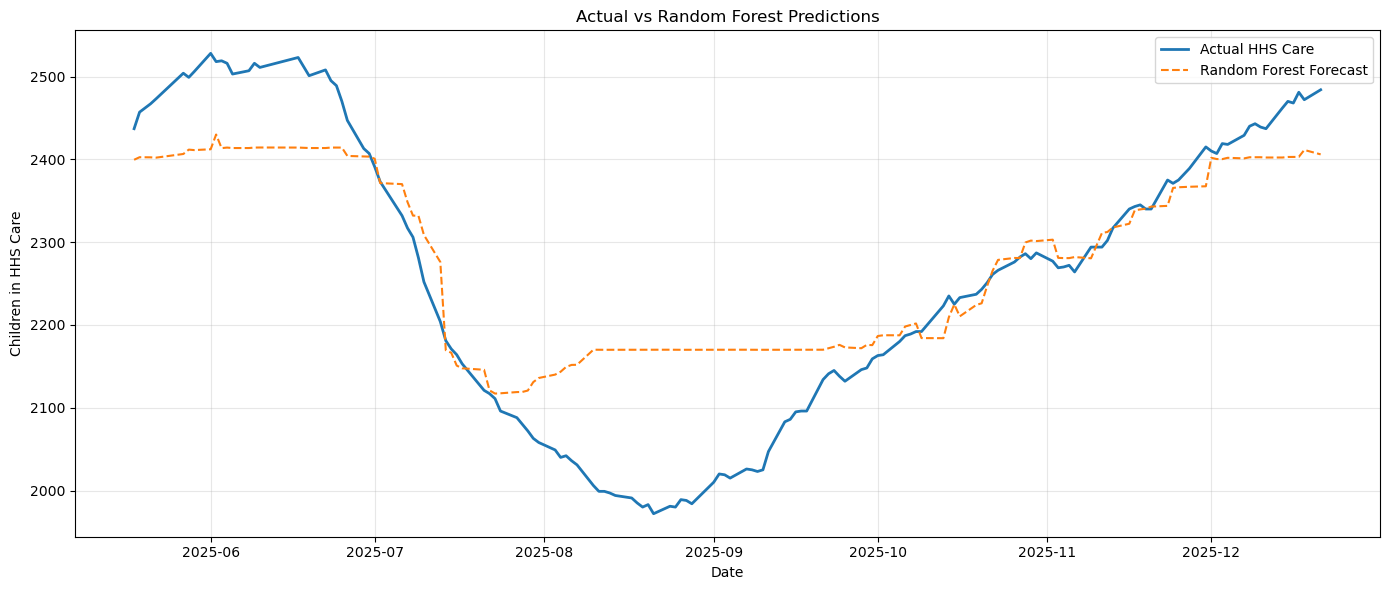

In [64]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf,
    y_test_rf.values,
    label="Actual HHS Care",
    linewidth=2)
plt.plot(
    test_dates_rf,
    rf_predictions,
    label="Random Forest Forecast",
    linestyle="--")
plt.title("Actual vs Random Forest Predictions")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Forecast","Moving Average","Random Forest"],
    "MAE": [
        mae,
        mae_ma,
        rf_mae],
    "RMSE": [
        rmse,
        rmse_ma,
        rf_rmse],
    "MAPE (%)": [
        mape,
        mape_ma,
        rf_mape]})
display(model_comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,186.51,227.23,8.76
1,Moving Average,33.25,40.61,1.48
2,Random Forest,62.72,85.17,2.91


In [ ]:
# Prepare discharge forecasting data

In [66]:
discharge_column = "Children discharged from HHS Care"

df_discharge = df_clean[
    ["Date", discharge_column]
].copy()
df_discharge = df_discharge.sort_values(
    "Date"
).reset_index(drop=True)
print("Discharge dataset shape:", df_discharge.shape)
print("\nMissing values:")
print(df_discharge.isnull().sum())

display(df_discharge.head(10))

Discharge dataset shape: (720, 2)

Missing values:
Date                                 0
Children discharged from HHS Care    0
dtype: int64


,Date,Children discharged from HHS Care
0,2023-01-12,436.00
1,2023-01-22,227.00
2,2023-01-23,181.00
3,2023-01-24,175.00
4,2023-01-25,180.00
5,2023-01-29,303.00
6,2023-01-30,196.00
7,2023-01-31,158.00
8,2023-02-01,231.00
9,2023-02-02,298.00


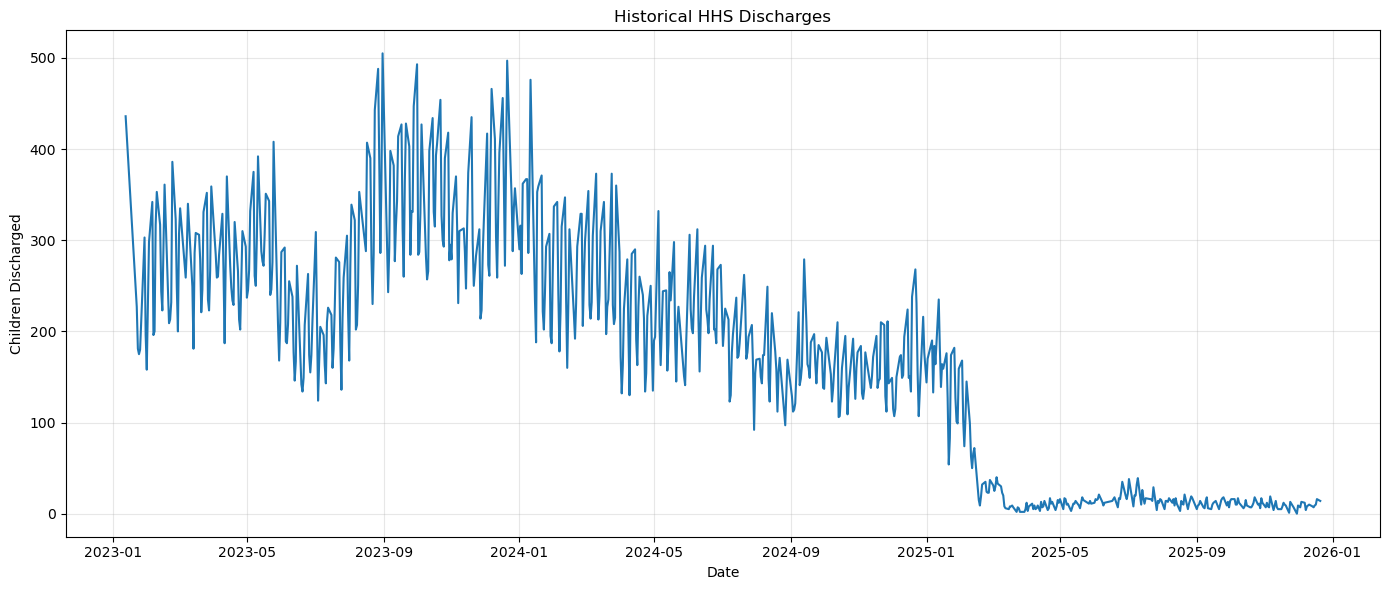

In [67]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_discharge["Date"],
    df_discharge[discharge_column],
    linewidth=1.5)
plt.title("Historical HHS Discharges")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [69]:
df_discharge_features = df_discharge.copy()
df_discharge_features["lag_1"] = (
    df_discharge_features[discharge_column].shift(1))
df_discharge_features["lag_7"] = (
    df_discharge_features[discharge_column].shift(7))
df_discharge_features["lag_14"] = (
    df_discharge_features[discharge_column].shift(14))
# Rolling averages using past observations only
df_discharge_features["rolling_mean_7"] = (
    df_discharge_features[discharge_column]
    .shift(1)
    .rolling(7)
    .mean())
df_discharge_features["rolling_mean_14"] = (
    df_discharge_features[discharge_column]
    .shift(1)
    .rolling(14)
    .mean())
df_discharge_features["day_of_week"] = (
    df_discharge_features["Date"].dt.dayofweek)
df_discharge_features["month"] = (
    df_discharge_features["Date"].dt.month)
display(df_discharge_features.head(15))

,Date,Children discharged from HHS Care,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,day_of_week,month
0,2023-01-12,436.00,<NA>,<NA>,<NA>,NaN,NaN,3,1
1,2023-01-22,227.00,436.00,<NA>,<NA>,NaN,NaN,6,1
2,2023-01-23,181.00,227.00,<NA>,<NA>,NaN,NaN,0,1
3,2023-01-24,175.00,181.00,<NA>,<NA>,NaN,NaN,1,1
4,2023-01-25,180.00,175.00,<NA>,<NA>,NaN,NaN,2,1
5,2023-01-29,303.00,180.00,<NA>,<NA>,NaN,NaN,6,1
6,2023-01-30,196.00,303.00,<NA>,<NA>,NaN,NaN,0,1
7,2023-01-31,158.00,196.00,436.00,<NA>,242.57,NaN,1,1
8,2023-02-01,231.00,158.00,227.00,<NA>,202.86,NaN,2,2
9,2023-02-02,298.00,231.00,181.00,<NA>,203.43,NaN,3,2


In [70]:
discharge_column = "Children discharged from HHS Care"
df_discharge = df_discharge.sort_values(
    "Date"
).reset_index(drop=True)
y_discharge = df_discharge[discharge_column]
split_index = int(len(df_discharge) * 0.80)
y_train_discharge = y_discharge.iloc[:split_index]
y_test_discharge = y_discharge.iloc[split_index:]
test_dates_discharge = df_discharge["Date"].iloc[split_index:]

print("Training observations:", len(y_train_discharge))
print("Testing observations:", len(y_test_discharge))
print("Training ends:", df_discharge["Date"].iloc[split_index - 1])
print("Testing starts:", test_dates_discharge.iloc[0])

Training observations: 576
Testing observations: 144
Training ends: 2025-05-13 00:00:00
Testing starts: 2025-05-14 00:00:00


In [71]:
naive_value_discharge = y_train_discharge.iloc[-1]
naive_predictions_discharge = pd.Series(
    naive_value_discharge,
    index=y_test_discharge.index)
print("Latest training discharge:", naive_value_discharge)
display(
    pd.DataFrame({
        "Date": test_dates_discharge.values,
        "Actual_Discharge": y_test_discharge.values,
        "Naive_Forecast": naive_predictions_discharge.values
    }).head(10))

Latest training discharge: 11.0


,Date,Actual_Discharge,Naive_Forecast
0,2025-05-14,11.00,11.00
1,2025-05-15,14.00,11.00
2,2025-05-18,9.00,11.00
3,2025-05-19,6.00,11.00
4,2025-05-21,18.00,11.00
5,2025-05-22,15.00,11.00
6,2025-05-27,11.00,11.00
7,2025-05-28,14.00,11.00
8,2025-05-29,11.00,11.00
9,2025-06-01,12.00,11.00


In [72]:
window_size = 7
history = list(y_train_discharge.values)
moving_avg_predictions_discharge = []
for actual_value in y_test_discharge.values:
    prediction = np.mean(history[-window_size:])
    moving_avg_predictions_discharge.append(prediction)
    history.append(actual_value)
moving_avg_predictions_discharge = pd.Series(
    moving_avg_predictions_discharge,
    index=y_test_discharge.index)
print("Moving Average Discharge Model created!")

display(
    pd.DataFrame({
        "Date": test_dates_discharge.values,
        "Actual_Discharge": y_test_discharge.values,
        "Moving_Average_Forecast": moving_avg_predictions_discharge.values
    }).head(10))

Moving Average Discharge Model created!


,Date,Actual_Discharge,Moving_Average_Forecast
0,2025-05-14,11.00,10.71
1,2025-05-15,14.00,9.86
2,2025-05-18,9.00,9.57
3,2025-05-19,6.00,9.43
4,2025-05-21,18.00,8.71
5,2025-05-22,15.00,10.86
6,2025-05-27,11.00,12.00
7,2025-05-28,14.00,12.00
8,2025-05-29,11.00,12.43
9,2025-06-01,12.00,12.00


In [73]:
discharge_feature_columns = ["lag_1","lag_7","lag_14","rolling_mean_7","rolling_mean_14","day_of_week","month"]
df_discharge_model = (
    df_discharge_features
    .dropna(subset=discharge_feature_columns + [discharge_column])
    .reset_index(drop=True))
X_discharge = df_discharge_model[discharge_feature_columns]
y_discharge_model = df_discharge_model[discharge_column]
split_index_rf = int(len(df_discharge_model) * 0.80)
X_train_discharge = X_discharge.iloc[:split_index_rf]
X_test_discharge = X_discharge.iloc[split_index_rf:]
y_train_discharge_rf = y_discharge_model.iloc[:split_index_rf]
y_test_discharge_rf = y_discharge_model.iloc[split_index_rf:]
test_dates_discharge_rf = (
    df_discharge_model["Date"].iloc[split_index_rf:])
print("Training rows:", len(X_train_discharge))
print("Testing rows:", len(X_test_discharge))

Training rows: 564
Testing rows: 142


In [74]:
rf_discharge_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42)
rf_discharge_model.fit(
    X_train_discharge,
    y_train_discharge_rf)
print("Random Forest Discharge Model trained successfully!")

Random Forest Discharge Model trained successfully!


In [83]:
rf_predictions_discharge = rf_discharge_model.predict(
    X_test_discharge)
rf_discharge_results = pd.DataFrame({
    "Date": test_dates_discharge_rf.values,
    "Actual_Discharge": y_test_discharge_rf.values,
    "Predicted_Discharge": rf_predictions_discharge})
display(rf_discharge_results.head(10))

,Date,Actual_Discharge,Predicted_Discharge
0,2025-05-18,9.00,6.98
1,2025-05-19,6.00,10.04
2,2025-05-21,18.00,11.13
3,2025-05-22,15.00,10.63
4,2025-05-27,11.00,12.18
5,2025-05-28,14.00,9.69
6,2025-05-29,11.00,9.36
7,2025-06-01,12.00,6.48
8,2025-06-02,16.00,11.33
9,2025-06-03,15.00,12.36


In [81]:
def evaluate_model(actual, predicted):
    mae_value = mean_absolute_error(
        actual,
        predicted)
    rmse_value = np.sqrt(
        mean_squared_error(actual, prdicted))
    nonzero_mask = actual != 0
    if nonzero_mask.any():
        mape_value = (
            np.abs((actual[nonzero_mask] - predicted[nonzero_mask])/ actual[nonzero_mask]).mean() * 100)
    else:
        mape_value = np.nan
    return {
        "MAE": mae_value,
        "RMSE": rmse_value,
        "MAPE (%)": mape_value}

In [86]:
def evaluate_model(actual, predicted):
    mae_value = mean_absolute_error(
        actual,
        predicted)
    rmse_value = np.sqrt(
        mean_squared_error(
            actual,
            predicted))
    nonzero_mask = actual != 0
    if nonzero_mask.any():
        mape_value = (
            np.abs(( actual[nonzero_mask]- predicted[nonzero_mask])
                / actual[nonzero_mask]
            ).mean() * 100)
    else:
        mape_value = np.nan
    return {
        "MAE": mae_value,
        "RMSE": rmse_value,
        "MAPE (%)": mape_value}
print("Evaluation function fixed successfully!")

Evaluation function fixed successfully!


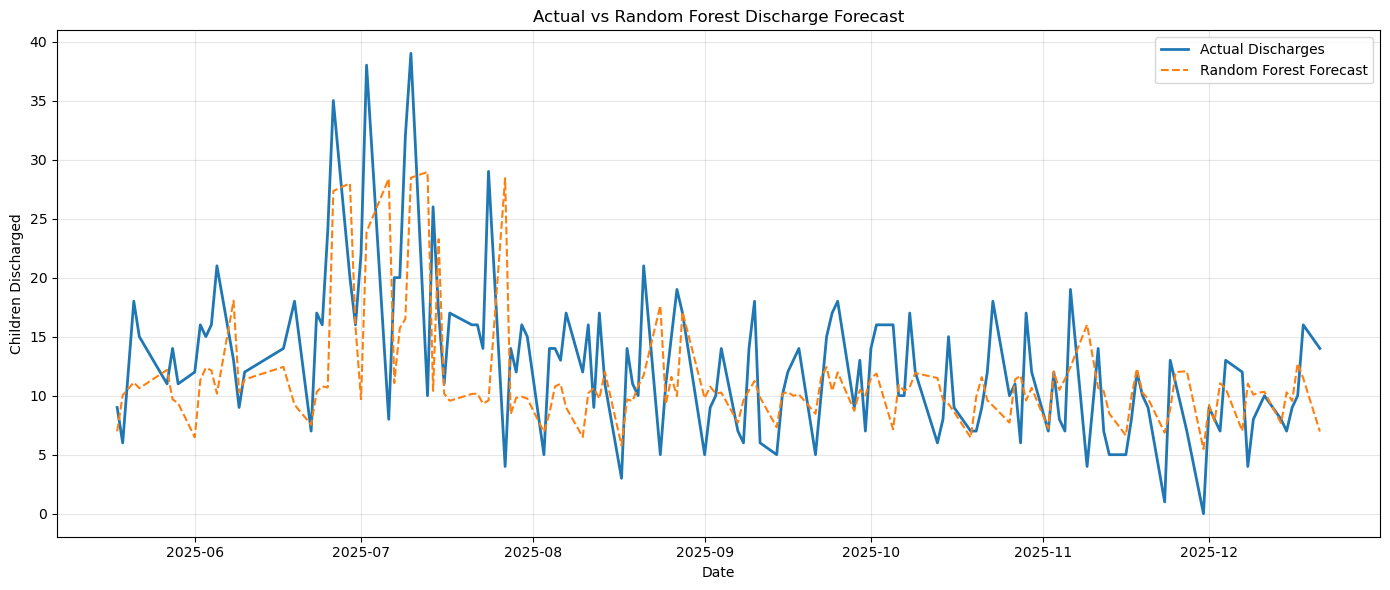

In [87]:
plt.figure(figsize=(14, 6))
plt.plot(
    test_dates_discharge_rf,
    y_test_discharge_rf.values,
    label="Actual Discharges",
    linewidth=2)
plt.plot(
    test_dates_discharge_rf,
    rf_predictions_discharge,
    label="Random Forest Forecast",
    linestyle="--")
plt.title("Actual vs Random Forest Discharge Forecast")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [89]:
recent_hhs = df_clean["Children in HHS Care"].dropna().tail(7)
hhs_average = recent_hhs.mean()
last_date = df_clean["Date"].max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=30,
    freq="D")
future_hhs = pd.DataFrame({
    "Date": future_dates,
    "Predicted_HHS_Care": hhs_average})
display(future_hhs.head(7))

,Date,Predicted_HHS_Care
0,2025-12-22,"2,467.71"
1,2025-12-23,"2,467.71"
2,2025-12-24,"2,467.71"
3,2025-12-25,"2,467.71"
4,2025-12-26,"2,467.71"
5,2025-12-27,"2,467.71"
6,2025-12-28,"2,467.71"


In [94]:
recent_discharge = (df_clean["Children discharged from HHS Care"].dropna().tail(7))
discharge_average = recent_discharge.mean()
future_discharge = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Discharges": discharge_average})
display(future_discharge.head(7))

,Date,Predicted_Discharges
0,2025-12-22,10.57
1,2025-12-23,10.57
2,2025-12-24,10.57
3,2025-12-25,10.57
4,2025-12-26,10.57
5,2025-12-27,10.57
6,2025-12-28,10.57


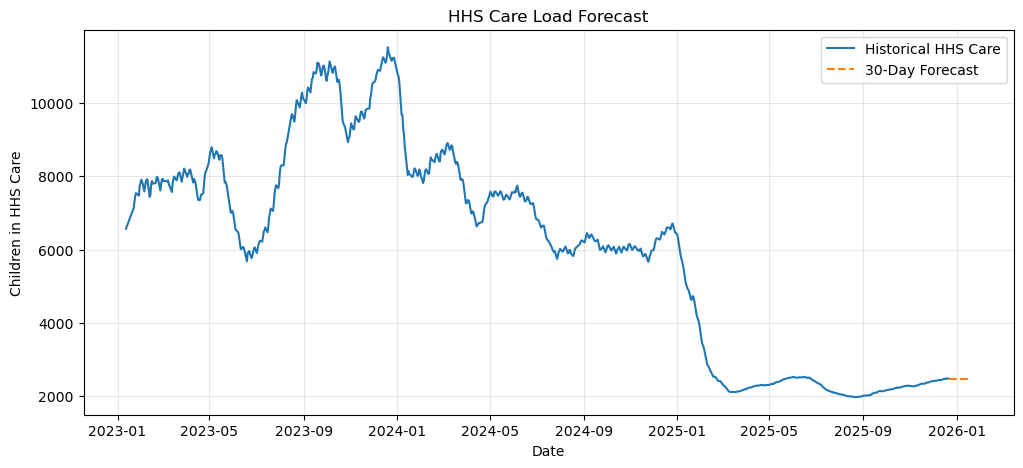

In [95]:
plt.figure(figsize=(12, 5))
plt.plot(
    df_clean["Date"],
    df_clean["Children in HHS Care"],
    label="Historical HHS Care"
)
plt.plot(
    future_hhs["Date"],
    future_hhs["Predicted_HHS_Care"],
    "--",
    label="30-Day Forecast"
)

plt.title("HHS Care Load Forecast")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [99]:
discharge_comparison = pd.DataFrame([{"Model": "Naive Forecast",**naive_metrics},
    {"Model": "Moving Average",**moving_average_metrics},
    {"Model": "Random Forest",**random_forest_metrics}])
display(discharge_comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,4.64,6.53,46.22
1,Moving Average,4.26,5.69,46.45
2,Random Forest,4.60,6.33,45.77


In [100]:
OUTPUT_DIR = Path.cwd() / "project_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
future_hhs.to_csv(
    OUTPUT_DIR / "HHS_Care_Forecast.csv",
    index=False)
future_discharge.to_csv(
    OUTPUT_DIR / "HHS_Discharge_Forecast.csv",
    index=False)
model_comparison.to_csv(
    OUTPUT_DIR / "HHS_Care_Model_Comparison.csv",
    index=False)
discharge_comparison.to_csv(
    OUTPUT_DIR / "HHS_Discharge_Model_Comparison.csv",
    index=False)
print("All forecast and comparison files saved!")
print("Folder:", OUTPUT_DIR.resolve())

All forecast and comparison files saved!
Folder: C:\Users\sohai\project_outputs
